In [1]:
# import paulssonlab.deaton.trenchripper.trenchripper as tr
# import trenchripper as tr
import trenchripper as tr

import warnings

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

import glob
import os
import shutil
import re
import pandas as pd
import h5py
import numpy as np
import skimage as sk
import matplotlib.pyplot as plt

import utilities

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
def merge_timepoints_and_channels_into_projection_image_for_single_fov(filenames_single_fov_all_channels_all_timepoints, channels, n_timepoints):


    def merge_timepoints_into_projection_image_for_single_channel(filenames_single_fov_channel_all_timepoints, n_timepoints):
        """
        Merges multiple timepoint images for a single channel into a single projection image.
        Args:
            filenames_single_fov_channel_all_timepoints (list): List of file paths for the images of a single channel across multiple timepoints.
        Returns:
            np.ndarray: A 2D array representing the projection image, where each pixel value is the 98th percentile across the timepoints.
        """
        # Open the first file to get the parameters
        assert len(filenames_single_fov_channel_all_timepoints) == n_timepoints, f"Expected {n_timepoints} timepoints for channel {filenames_single_fov_channel_all_timepoints[0]}, found {len(filenames_single_fov_channel_all_timepoints)}"
        first_file = filenames_single_fov_channel_all_timepoints[0]
        with h5py.File(first_file, 'r') as f:
            # Get the shape of the image
            height, width = f['data'].shape
        # Create an empty array to hold the merged image
        images_all_timepoints = np.empty((n_timepoints, height, width), dtype='uint16')
        # Loop through each file and read the data
        for i, filename in enumerate(filenames_single_fov_channel_all_timepoints):
            with h5py.File(filename, 'r') as f:
                # Read the data and store it in the array
                images_all_timepoints[i] = f['data'][:]

        image_projection = np.percentile(images_all_timepoints, 98, axis=0) / np.max(images_all_timepoints)
        return image_projection

    n_channels = len(channels)
    assert set(channels) == set (filenames_single_fov_all_channels_all_timepoints.keys()), f"Expected channels {channels}, found {filenames_single_fov_all_channels_all_timepoints.keys()}"
    with h5py.File(filenames_single_fov_all_channels_all_timepoints[channels[0]][0], 'r') as f:
        # print(1)
        height, width = f['data'].shape
        # print(f"Height: {height}, Width: {width}")

    merged_image_all_channels = np.empty((n_channels, height, width))

    for i, channel in enumerate(channels):
        filenames_single_fov_channel_all_timepoints = filenames_single_fov_all_channels_all_timepoints[channel]
        assert len(filenames_single_fov_channel_all_timepoints) == n_timepoints, f"Expected {n_timepoints} timepoints for channel {channel}, found {len(filenames_single_fov_channel_all_timepoints)}"
        merged_image_all_channels[i] = merge_timepoints_into_projection_image_for_single_channel(filenames_single_fov_channel_all_timepoints, n_timepoints)

    image_projection = \
            sk.util.img_as_uint(
                np.percentile(
                    merged_image_all_channels, 98, axis=0
                )
            )
    
    return image_projection

def make_and_save_projection_image_single_fov(fov,
                                              filenames_per_fov_channel_all_timepoints,
                                              channels,
                                              n_timepoints,
                                              merged_channel_name = 'SEG',
                                              template_channel_name = 'RFP'):
    
    filenames_single_fov_all_channels_all_timepoints = filenames_per_fov_channel_all_timepoints[fov]
    image_projection = merge_timepoints_and_channels_into_projection_image_for_single_fov(filenames_single_fov_all_channels_all_timepoints, channels, n_timepoints)
    
    merged_channel_filenames = [filename.replace('_config='+template_channel_name, '_config='+merged_channel_name) for filename in filenames_single_fov_all_channels_all_timepoints[template_channel_name]]


    # Save image projection into all the filenames
    for filename in merged_channel_filenames:
        with h5py.File(filename, 'w') as f:
            f.create_dataset('data', data=image_projection, dtype='uint16')
        print(f"Saved merged image to {filename}")
    return 0

In [4]:
headpath = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Barcodes/'
headpath_run = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/'

# filenames_per_fov_all_channels_all_timepoints = utilities.group_filenames_per_fov(headpath = headpath_run, pattern="*fov=*")
CHANNELS = ['BF', 'RFP', 'Cy5', 'Cy7']
CHANNELS_TO_MERGE = ['RFP', 'Cy5', 'Cy7']
N_TIMEPOINTS = 10
MERGED_CHANNEL_NAME = 'SEG'
TEMPLATE_CHANNEL_NAME = 'RFP'

filenames_per_fov_channel_all_timepoints = utilities.group_filenames_per_fov_channel_all_timepoints(headpath = headpath_run, pattern="*fov*", n_timepoints= N_TIMEPOINTS, channels = CHANNELS)
filenames_per_fov_channel_all_timepoints = {fov: {channel: filenames_per_fov_channel_all_timepoints[fov][channel] for channel in CHANNELS_TO_MERGE} for fov in filenames_per_fov_channel_all_timepoints}

AssertionError: Channel SEG not in ['BF', 'RFP', 'Cy5', 'Cy7']

In [20]:
# Save image
fov = 0
channels = CHANNELS_TO_MERGE

# filenames_single_fov_all_channels_all_timepoints = filenames_per_fov_channel_all_timepoints[fov]

make_and_save_projection_image_single_fov(fov,
                                          filenames_per_fov_channel_all_timepoints,
                                          channels = channels,
                                          n_timepoints = N_TIMEPOINTS,
                                          merged_channel_name = MERGED_CHANNEL_NAME,
                                          template_channel_name = TEMPLATE_CHANNEL_NAME)

Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=1.hdf5
Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=2.hdf5
Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=3.hdf5
Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=4.hdf5
Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=5.hdf5
Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=6.hdf5
Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=7.hdf5
Saved merged image to /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fo

0

In [5]:
indices = filenames_per_fov_channel_all_timepoints.keys()
assert indices==set(range(len(indices))), f"Expected indices to be a range, found {indices}"

NameError: name 'filenames_per_fov_channel_all_timepoints' is not defined

In [7]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:30:00",
    local=False,
    n_workers=200,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

20m
0:30:00


In [8]:
df_futures = utilities.deploy_function_in_dask(dask_controller = dask_controller,
                                     headpath = headpath,
                                     function = make_and_save_projection_image_single_fov,
                                     indices = indices,
                                     filenames_per_fov_channel_all_timepoints = filenames_per_fov_channel_all_timepoints,
                                    channels = CHANNELS_TO_MERGE,
                                    n_timepoints = N_TIMEPOINTS,
                                    merged_channel_name = MERGED_CHANNEL_NAME,
                                    template_channel_name = TEMPLATE_CHANNEL_NAME)

(2960, 2960)


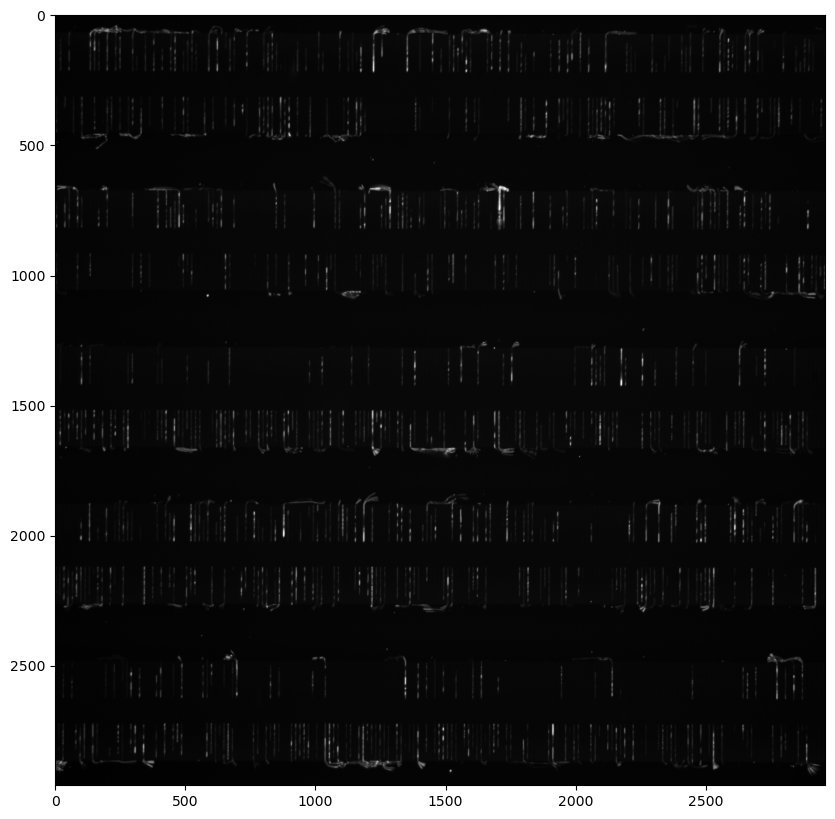

In [7]:
with h5py.File('/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=125_config=SEG_t=10.hdf5', 'r') as f:
    image_projection = f['data'][:]
    print(image_projection.shape)
    plt.imshow(image_projection, cmap='gray')

### Change metadata files

In [8]:
metadata_filenames = glob.glob(headpath_run + '*metadata*')
metadata_filenames

['/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_1.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_10.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_2.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_3.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_4.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_5.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_6.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_7.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_8.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/metadata_9.hdf5']

In [8]:
utilities.add_fake_channel_to_all_metadata_files(metadata_filenames, config_template='BF', config_new=MERGED_CHANNEL_NAME)

0

In [9]:
pd.read_hdf(metadata_filenames[0])

,config,fov,t,x,y,z
0,BF,0,0.557,7396.0,14167.9,2814.26
1,SEG,0,0.557,7396.0,14167.9,2814.26
2,RFP,0,11.259,7396.0,14167.9,2814.28
3,Cy5,0,13.630,7396.0,14167.9,2814.28
4,Cy7,0,16.001,7396.0,14167.9,2814.26
...,...,...,...,...,...,...
3140,BF,628,5104.373,-15607.9,24380.9,2815.90
3141,SEG,628,5104.373,-15607.9,24380.9,2815.90
3142,RFP,628,5106.807,-15608.0,24380.9,2815.88
3143,Cy5,628,5109.179,-15608.0,24380.9,2815.98


NameError: name 'qq' is not defined